# Лабораторная работа № 01 — прикладная статистика
## Sprint 1. Как шрифты влияют на размещение текста

**Цель:** сравнить, сколько места занимает один и тот же текст в разных шрифтах.

<a id="data"></a>
## 1. Данные и эксперимент

Использованы отрывки из первых глав трёх книг: «Алиса в Стране чудес», «Гордость и предубеждение», «Приключения Шерлока Холмса». Тексты взяты из Project Gutenberg, очищены от оформления и разделены на короткие фрагменты. Из каждого произведения случайно выбрано 18 фрагментов, всего 54.

**Эксперимент:** выбираем один из 54 фрагментов с равной вероятностью $1/54$ и измеряем его в шрифте **DejaVu Serif**. При повторении эксперимента может попасться другой текст, поэтому результаты случайны. После выбора конкретного текста измерение уже детерминированно.

Для сравнения шрифтов каждый фрагмент дополнительно набран в **DejaVu Sans** и **DejaVu Sans Mono**. Условия одинаковые: лист А4, поля 20 мм, кегль 12 pt, межстрочный интервал 1,4. Перенос — по словам, без выравнивания по ширине и переносов внутри слов.

Таблицы `data/fragments.csv` и `data/layout.csv` содержат соответственно исходные фрагменты и результаты измерений. Алгоритм — в `src/build_data.py` и `src/measurement.py`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Image

plt.rcParams.update({
    "figure.figsize": (9, 4), "font.size": 11,
    "axes.grid": True, "grid.alpha": 0.18,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 115
})

cols = {"chars": "Символы, шт.", "lines": "Строки, шт.", "ink_cm2": "Площадь текста, см²"}

texts = pd.read_csv("data/fragments.csv")
layout = pd.read_csv("data/layout.csv")
base = layout[layout.font == "DejaVu Serif"].reset_index(drop=True)
print("Фрагментов:", len(texts), "| Измерений:", len(layout))
display(texts.assign(text=texts.text.str.slice(0, 85) + "…")[["id", "book", "text"]].head(4))

Фрагментов: 54 | Измерений: 162


,id,book,text
0,alice-01,Алиса в Стране чудес,"In another moment down went Alice after it, ne..."
1,alice-02,Алиса в Стране чудес,"Oh, how I wish I could shut up like a telescop..."
2,alice-03,Алиса в Стране чудес,"Alice was not a bit hurt, and she jumped up on..."
3,alice-04,Алиса в Стране чудес,"She felt that she was dozing off, and had just..."


### Как получено одно наблюдение

`chars` — число символов (включая пробелы); `words` — число слов; `lines` — число строк после переноса; `ink_cm2` — суммарная площадь закрашенных пикселей букв в см². Для площади текст рисуется при 144 dpi, затем интенсивности пикселей переводятся в см².

$$S_{\text{ink}} = \frac{1}{255}\sum_{i=1}^{P} I_i\left(\frac{2.54}{144}\right)^2, \quad I_i\in[0,255].$$

In another moment down went Alice after it, never once considering how in the world she was to get out again. The rabbit-hole went straight on like a tunnel for some way, and then dipped suddenly down, so suddenly that Alice had not a moment to think about sto…
DejaVu Serif → (5, 5.0469)
DejaVu Sans Mono → (6, 5.7309)


,id,book,font,chars,words,lines,ink_cm2
0,alice-01,Алиса в Стране чудес,DejaVu Serif,329,60,5,5.0469
1,alice-01,Алиса в Стране чудес,DejaVu Sans,329,60,5,5.7457
2,alice-01,Алиса в Стране чудес,DejaVu Sans Mono,329,60,6,5.7309


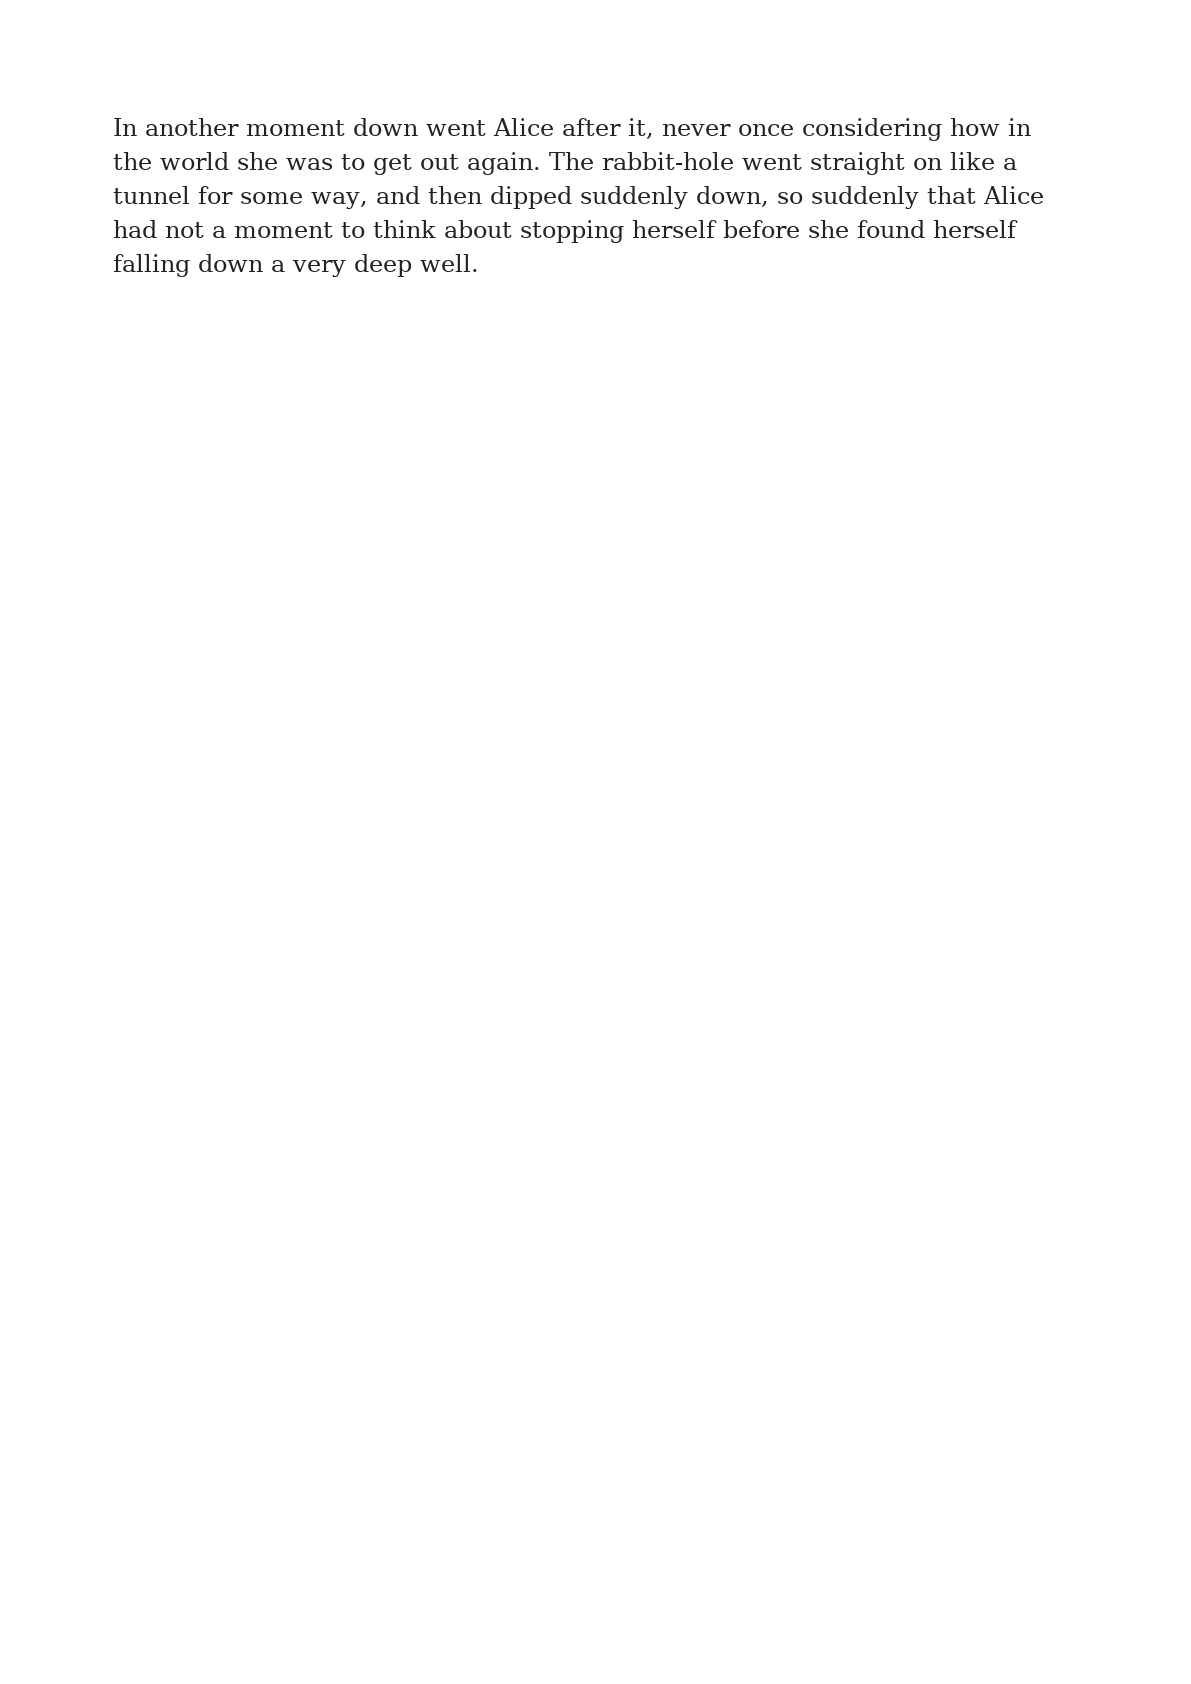

In [2]:
from src.measurement import load_font, measure

text = texts.loc[0, "text"]
print(text[:260] + ("…" if len(text) > 260 else ""))
for name in ["DejaVu Serif", "DejaVu Sans Mono"]:
    print(name, "→", measure(text, load_font(name)))
display(layout[layout.id == texts.loc[0, "id"]])
display(Image(filename="figures/example_a4.png", width=280))

<a id="rv1"></a>
## 2. Random Variable 01 — количество символов $X$
### Description

$X$ — число символов в случайно выбранном фрагменте. Это дискретная величина.

### EDA & Distribution

Эмпирическая вероятность: $\hat P(X=k)=n_k/N$, где $n_k$ — число фрагментов длины $k$.

,Символы
count,54.00
mean,261.28
std,124.12
min,95.00
25%,179.00
50%,231.50
75%,302.00
max,733.00


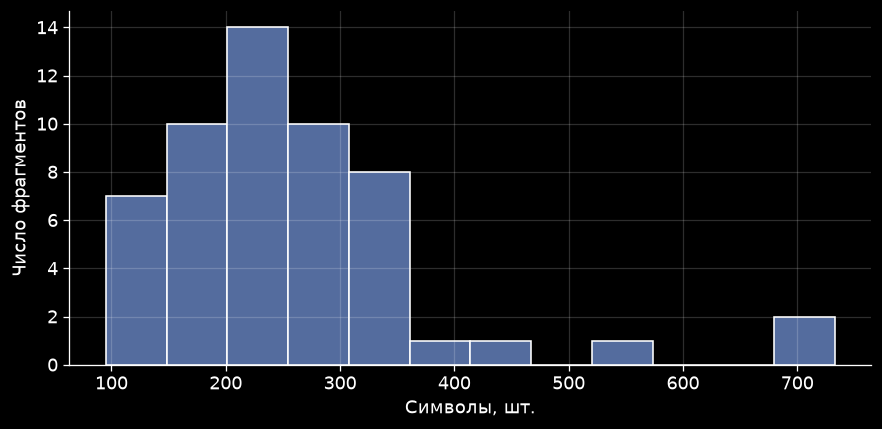

In [3]:
display(base["chars"].describe().round(2).to_frame("Символы"))
ax = base.chars.hist(bins=12, color="#546C9E", edgecolor="white")
ax.set(xlabel="Символы, шт.", ylabel="Число фрагментов")
plt.show()

<a id="rv2"></a>
## 3. Random Variable 02 — количество строк $Y$
### Description

$Y$ — число строк, которое занимает выбранный фрагмент в DejaVu Serif. Результат целочисленный.

### EDA & Distribution

Вероятность $\hat P(Y=k)$ оцениваем долей фрагментов, занявших $k$ строк.

,Строки
count,54.00
mean,3.85
std,1.68
min,2.00
25%,3.00
50%,3.00
75%,4.75
max,10.00


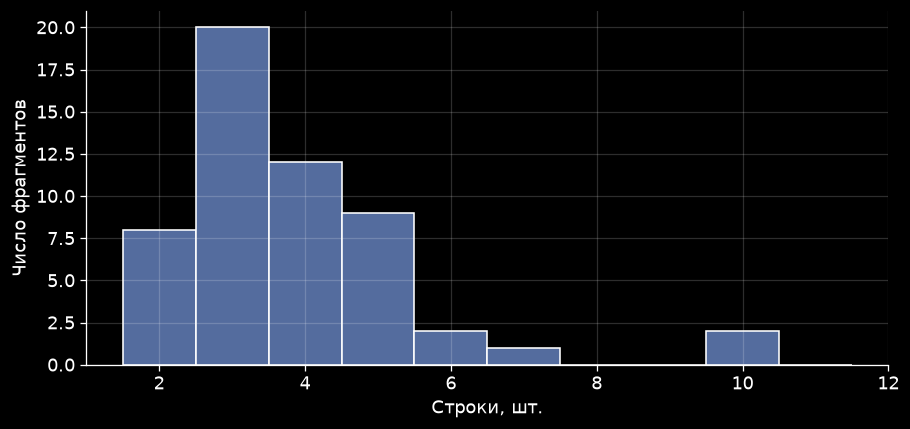

In [4]:
display(base["lines"].describe().round(2).to_frame("Строки"))
ax = base.lines.hist(bins=np.arange(1.5, base.lines.max()+1.6), color="#546C9E", edgecolor="white")
ax.set(xlabel="Строки, шт.", ylabel="Число фрагментов")
plt.show()

<a id="rv3"></a>
## 4. Random Variable 03 — площадь текста $Z$
### Description

$Z$ — суммарная площадь закрашенных пикселей выбранного фрагмента. Значения измеряются в см², с точностью до разрешения изображения.

### EDA & Distribution

Используем эмпирическую функцию распределения:

$$\hat F_Z(z)=\frac1N\sum_{i=1}^N\mathbf 1(Z_i\le z).$$

Не предполагаем заранее, что распределение нормальное.

,"Площадь, см²"
count,54.00
mean,3.87
std,1.84
min,1.34
25%,2.62
50%,3.47
75%,4.50
max,10.62


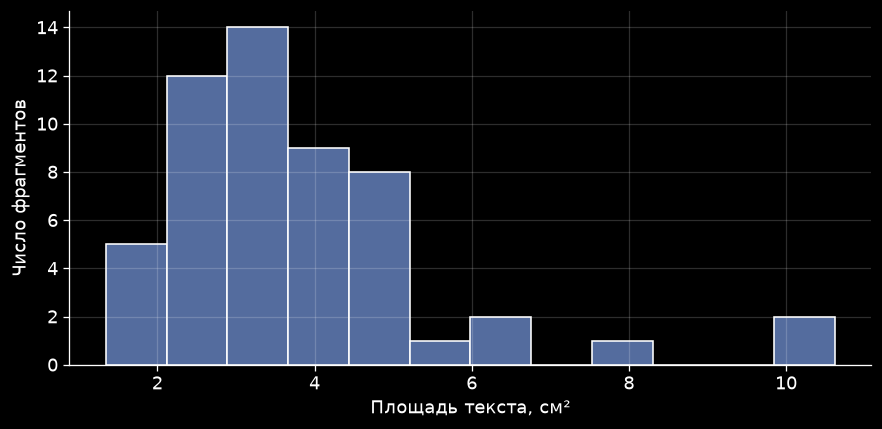

In [5]:
display(base["ink_cm2"].describe().round(2).to_frame("Площадь, см²"))
ax = base.ink_cm2.hist(bins=12, color="#546C9E", edgecolor="white")
ax.set(xlabel="Площадь текста, см²", ylabel="Число фрагментов")
plt.show()

**Вывод.** Размеры фрагментов различаются. Число строк меняется скачками, а площадь текста зависит от формы и количества букв.

<a id="depend"></a>
## 5. Зависимость и нормализация

Проверим связь между $X$, $Y$ и $Z$ по коэффициенту Спирмена. Он показывает, насколько согласованно меняются значения, но не доказывает причинную связь.

         chars  lines  ink_cm2
chars     1.00   0.96     1.00
lines     0.96   1.00     0.96
ink_cm2   1.00   0.96     1.00
X и Y: rho = 0.964; p = 1.35e-31


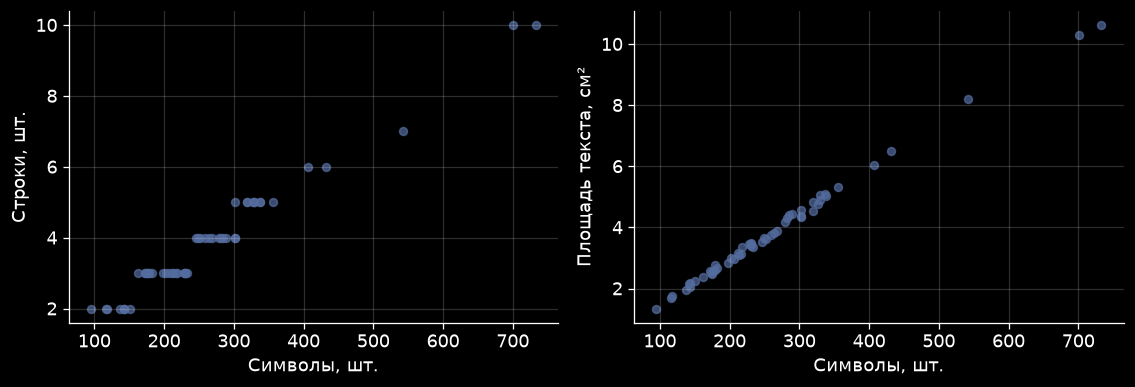

In [6]:
print(base[list(cols)].corr(method="spearman").round(2))
rho, p_rho = stats.spearmanr(base.chars, base.lines)
print(f"X и Y: rho = {rho:.3f}; p = {p_rho:.3g}")
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, col, title in zip(axs, ["lines", "ink_cm2"], ["Строки, шт.", "Площадь текста, см²"]):
    ax.scatter(base.chars, base[col], s=24, alpha=0.7, color="#546C9E")
    ax.set_xlabel("Символы, шт.")
    ax.set_ylabel(title)
fig.tight_layout()
plt.show()

Длина текста ожидаемо связана с числом строк и площадью. Чтобы сравнить величины с разными единицами измерения, используем $z$-оценку:

$$z_i = \frac{x_i-\overline x}{s}, \quad s^2=\frac{1}{N-1}\sum_{i=1}^{N}(x_i-\overline x)^2.$$

Это изменение шкалы, а не превращение данных в нормальное распределение. Для гипотезы ниже берём исходные числа строк.

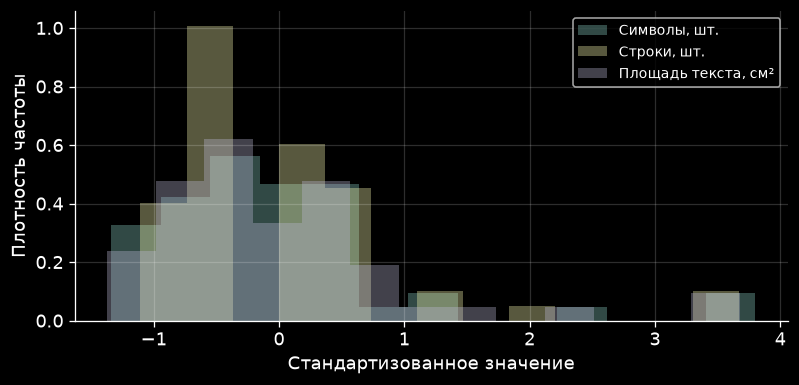

In [7]:
z = (base[list(cols)] - base[list(cols)].mean()) / base[list(cols)].std(ddof=1)
fig, ax = plt.subplots(figsize=(8, 3.5))
for col in cols:
    ax.hist(z[col], bins=13, density=True, alpha=0.35, label=cols[col])
ax.set_xlabel("Стандартизованное значение")
ax.set_ylabel("Плотность частоты")
ax.legend(fontsize=9)
plt.show()

<a id="sample"></a>
## 6. Выборка и состоятельность

Генеральная совокупность **в этой работе** — все 54 выбранных фрагмента, а не все книги в мире. Берём выборку **без возвращения**, потому что один и тот же фрагмент не должен учитываться дважды.

Среднее по выборке: $\overline X_n = \frac1n\sum_{i=1}^n X_i$. Для конечной совокупности при случайном отборе без возвращения:

$$\operatorname{Var}(\overline X_n)=\frac{S^2}{n}\left(1-\frac{n}{N}\right).$$

Проверим на повторных выборках: с ростом $n$ ошибка среднего должна уменьшаться.

,Все 54 (среднее),Выборка 20 (среднее),Все 54 (ст. откл.),Выборка 20 (ст. откл.)
chars,261.28,248.90,124.12,72.52
lines,3.85,3.70,1.68,0.98
ink_cm2,3.87,3.69,1.84,1.09


,chars,lines,ink_cm2
n,,,
6,0.354,0.355,0.356
12,0.253,0.254,0.253
20,0.179,0.180,0.179
35,0.102,0.102,0.102
50,0.040,0.040,0.040
54,0.000,0.000,0.000


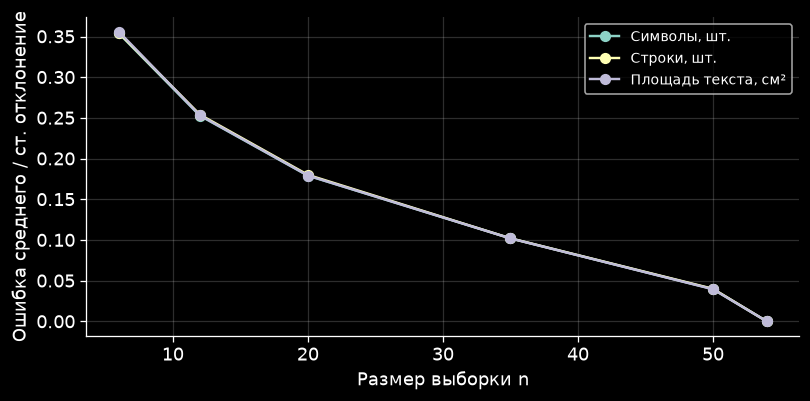

In [8]:
part = base.sample(n=20, random_state=18)
comparison = pd.DataFrame({"Все 54 (среднее)": base[list(cols)].mean(),
                           "Выборка 20 (среднее)": part[list(cols)].mean(),
                           "Все 54 (ст. откл.)": base[list(cols)].std(ddof=1),
                           "Выборка 20 (ст. откл.)": part[list(cols)].std(ddof=1)})
display(comparison.round(2))

rng = np.random.default_rng(18)
features = list(cols)
N = len(base)
size = [6, 12, 20, 35, 50, N]
true_mean = base[features].mean()
true_std = base[features].std(ddof=1)
rows = []
for n in size:
    errors = []
    for _ in range(400):
        sample = base.iloc[rng.choice(N, n, replace=False)]
        errors.append(((sample[features].mean() - true_mean) / true_std).to_numpy())
    rmse = np.sqrt(np.mean(np.array(errors) ** 2, axis=0))
    rows.append([n, *rmse])
err = pd.DataFrame(rows, columns=["n", *features]).set_index("n")
display(err.round(3))
ax = err.plot(marker="o", figsize=(8, 3.6))
ax.set_xlabel("Размер выборки n")
ax.set_ylabel("Ошибка среднего / ст. отклонение")
ax.legend([cols[c] for c in features], fontsize=9)
plt.show()

**Вывод.** Средние в небольших выборках колеблются. При увеличении $n$ ошибка обычно уменьшается, а при $n=N$ равна нулю. Это эмпирическая иллюстрация состоятельности оценки среднего для данной конечной совокупности.

<a id="hypothesis"></a>
## 7. Проверка гипотезы: влияет ли шрифт на число строк?

Берём **одни и те же 54 фрагмента** в DejaVu Serif и DejaVu Sans Mono. Для каждого фрагмента считаем разницу $D=Y_{\text{Mono}}-Y_{\text{Serif}}$.

- $H_0$: среди ненулевых разниц положительные и отрицательные встречаются одинаково часто.
- $H_1$: моноширинный шрифт чаще даёт больше строк.

Используем односторонний **биномиальный критерий знаков**, уровень значимости $\alpha=0.05$. Нулевые разницы не учитываются при подсчёте знаков.

Больше строк: 33, меньше: 0, одинаково: 21
Средняя разница: 0.65 строки; p = 1.16e-10
H0 отвергается


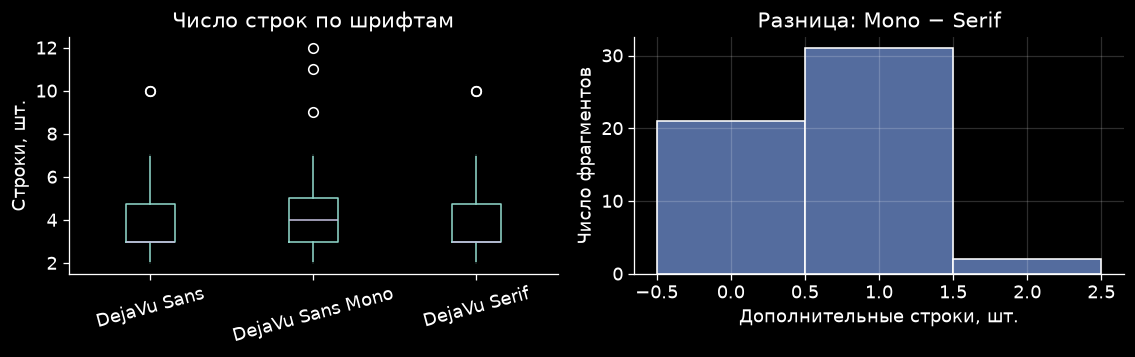

In [9]:
wide = layout.pivot(index="id", columns="font", values="lines")
diff = wide["DejaVu Sans Mono"] - wide["DejaVu Serif"]
pos, neg, zero = (diff > 0).sum(), (diff < 0).sum(), (diff == 0).sum()
pvalue = stats.binomtest(int(pos), int(pos + neg), p=0.5, alternative="greater").pvalue
print(f"Больше строк: {pos}, меньше: {neg}, одинаково: {zero}")
print(f"Средняя разница: {diff.mean():.2f} строки; p = {pvalue:.3g}")
print("H0 отвергается" if pvalue < 0.05 else "Недостаточно оснований отвергнуть H0")

fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
layout.boxplot(column="lines", by="font", ax=axs[0], grid=False)
axs[0].set_title("Число строк по шрифтам")
axs[0].set_xlabel("")
axs[0].set_ylabel("Строки, шт.")
axs[0].tick_params(axis="x", rotation=15)
axs[1].hist(diff, bins=np.arange(-0.5, diff.max() + 1.5), color="#546C9E", edgecolor="white")
axs[1].set_title("Разница: Mono − Serif")
axs[1].set_xlabel("Дополнительные строки, шт.")
axs[1].set_ylabel("Число фрагментов")
fig.suptitle("")
fig.tight_layout()
plt.show()

**Вывод.** На выбранных текстах DejaVu Sans Mono чаще занимает больше строк, чем DejaVu Serif. Это сравнение относится к конкретным шрифтам и условиям набора; для всех шрифтов такой вывод делать нельзя.

<a id="extra"></a>
## 8. Дополнительный датасет КТвД — цветы ириса

В датасете Iris есть измерения 150 цветов. Случайно выбираем один цветок и рассматриваем две величины: длину и ширину лепестка.

Наблюдений: 150; rho = 0.938; p = 8.16e-70


,petal_length_cm,petal_width_cm,species_id
0,1.4,0.2,0
1,1.4,0.2,0
2,1.3,0.2,0
3,1.5,0.2,0


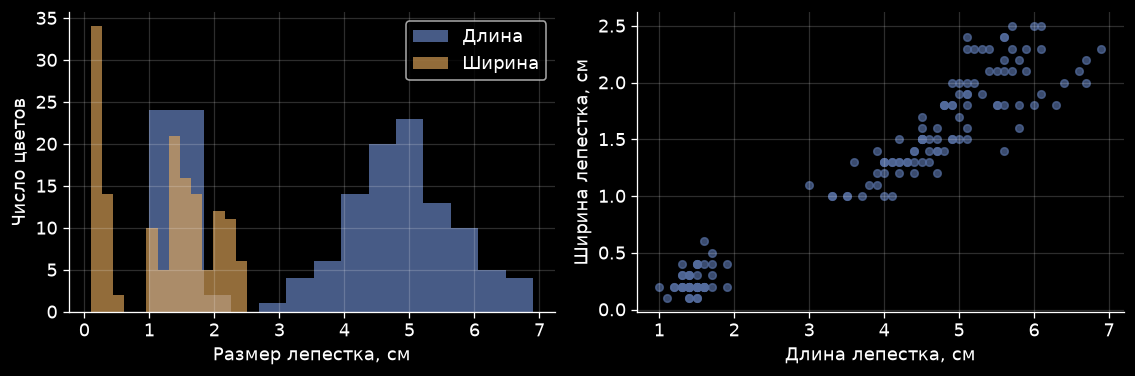

In [10]:
iris = pd.read_csv("data/iris.csv")
rho, pv = stats.spearmanr(iris.petal_length_cm, iris.petal_width_cm)
print(f"Наблюдений: {len(iris)}; rho = {rho:.3f}; p = {pv:.3g}")
display(iris.head(4))
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
axs[0].hist(iris.petal_length_cm, bins=14, color="#546C9E", alpha=0.85, label="Длина")
axs[0].hist(iris.petal_width_cm, bins=14, color="#E2A75A", alpha=0.65, label="Ширина")
axs[0].set_xlabel("Размер лепестка, см")
axs[0].set_ylabel("Число цветов")
axs[0].legend()
axs[1].scatter(iris.petal_length_cm, iris.petal_width_cm, s=22, alpha=0.7, color="#546C9E")
axs[1].set_xlabel("Длина лепестка, см")
axs[1].set_ylabel("Ширина лепестка, см")
fig.tight_layout()
plt.show()

**Вывод.** Длина и ширина лепестка положительно связаны. Но в данных есть три вида ирисов, поэтому часть связи может объясняться различиями между видами.

## 9. Lab resume

В ходе исследования выяснилось:

1. Один и тот же текст занимает разное количество строк в зависимости от шрифта.
2. Количество символов, строк и площадь текста связаны между собой.
3. При увеличении выборки средние значения в эксперименте приближаются к средним всего набора данных.
4. Моноширинный шрифт в среднем занимает больше строк, чем обычный. Различие статистически значимо (p < 0,05).

### cat_mark_table

| cat_id | notebook_link | coeff | comment |
|---|---|---|---|
| 1 — Случайные величины | §2–4 | — | 3 величины, распределения |
| 2 — EDA | §4–5 | — | Статистики, графики, нормализация |
| 3 — Зависимость | §5 | — | Корреляция |
| 4 — Выборка | §6 | — | Состоятельность оценок |
| 5 — Гипотеза | §7 | — | Критерий знаков |
| 6 — Доп. датасет | §8 | — | Iris |

### Источники

1. Lewis Carroll — [Alice's Adventures in Wonderland](https://www.gutenberg.org/ebooks/11).
2. Jane Austen — [Pride and Prejudice](https://www.gutenberg.org/ebooks/1342).
3. Arthur Conan Doyle — [The Adventures of Sherlock Holmes](https://www.gutenberg.org/ebooks/1661).
4. [Iris Dataset — UCI](https://archive.ics.uci.edu/dataset/53/iris).
